# Module 2 — Survival Analysis of Order Fulfillment

## Business question
What is the "life expectancy" of an order until delivery, and which factors accelerate or
delay that time-to-event? This captures the full time dynamic, not just a binary delay label.

## Framing
- **Duration:** `Days for shipping (real)` — days from order creation to actual shipment.
- **Event:** shipment completed.
- **Censoring:** this historical extract has zero missing shipment dates — every order in the
  dataset is fully observed (no right-censoring), a limitation Section 8 states explicitly;
  a live operational system would have in-flight orders subject to real censoring.

## 1. Setup & imports

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from lifelines import KaplanMeierFitter, CoxPHFitter

from survival import fit_km_by_group, logrank_between_two_groups, fit_cox_model

pd.set_option('display.max_columns', 100)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)


## 2. Load data and build the time-to-event table

In [2]:
df = pd.read_csv('../data/raw/DataCoSupplyChainDataset.csv', encoding='latin1')
df.columns = [c.strip() for c in df.columns]
df['order date (DateOrders)'] = pd.to_datetime(df['order date (DateOrders)'], errors='coerce')
df['order_month'] = df['order date (DateOrders)'].dt.month

df['duration'] = df['Days for shipping (real)']
df['event_observed'] = 1  # fully observed in this historical extract, see Section 8

print(f"Missing shipping dates: {df['shipping date (DateOrders)'].isna().sum()} (0 expected)")
df[['Shipping Mode', 'duration', 'event_observed']].head()


Missing shipping dates: 0 (0 expected)


,Shipping Mode,duration,event_observed
0,Standard Class,3,1
1,Standard Class,5,1
2,Standard Class,4,1
3,Standard Class,3,1
4,Standard Class,2,1


## 3. Kaplan-Meier curves by shipping mode

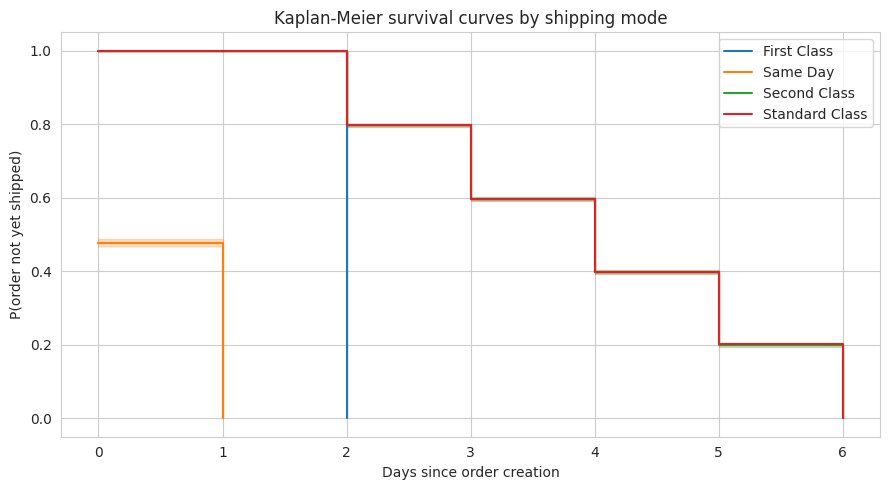

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
kmf = KaplanMeierFitter()
for mode, group in df.groupby('Shipping Mode'):
    kmf.fit(group['duration'], group['event_observed'], label=mode)
    kmf.plot_survival_function(ax=ax)

ax.set_xlabel('Days since order creation')
ax.set_ylabel('P(order not yet shipped)')
ax.set_title('Kaplan-Meier survival curves by shipping mode')
plt.tight_layout()
plt.savefig('../reports/figures/module2_km_by_mode.png', dpi=120)
plt.show()


Same Day drops to zero almost immediately (orders ship within 0–1
days). First Class is a near-vertical step at day 2 — consistent with the zero-variance
scheduling artifact already documented in Module 1. Second Class and Standard Class both decay
over a similar multi-day range, which motivates the direct statistical comparison below.

## 4. Log-rank test: Second Class vs Standard Class
Both modes showed a large gap in *delay relative to their own promise* in Module 1. Here we test whether their *absolute* time-to-shipment differs.

In [4]:
lr_result = logrank_between_two_groups(
    df, 'duration', 'event_observed', 'Shipping Mode', 'Second Class', 'Standard Class'
)
print(f"Log-rank test statistic: {lr_result.test_statistic:.4f}")
print(f"p-value: {lr_result.p_value:.4f}")


Log-rank test statistic: 0.6814
p-value: 0.4091


**Finding:** the log-rank test does **not** reject the null hypothesis of equal survival
curves (p ≈ 0.41). In absolute terms, Second Class and Standard Class orders take a
statistically indistinguishable number of days to ship (~4 days on average for both).

It complements Module 1's finding rather than contradicting it: Module 1 showed Second Class
breaks its *own, tighter promise* by ~2 more days than Standard Class breaks its looser one — a
finding about promise-keeping. In absolute wall-clock time, both modes take a similar
number of days to fulfill from the operation's side. Together, the two results
suggest the gap in Module 1 is a **scheduling-promise problem** (Second Class is promised a
window it structurally cannot meet as reliably as Standard Class's more generous window),
rather than a difference in actual operational speed.

## 5. Cox Proportional Hazards model
Multivariate hazard ratios controlling for shipping mode, region, customer segment, and order month.

In [5]:
covariates_cat = ['Shipping Mode', 'Order Region', 'Customer Segment']
df_cox = df[['duration', 'event_observed', 'order_month'] + covariates_cat].dropna().copy()

dummies = pd.get_dummies(df_cox[covariates_cat], drop_first=True)
df_cox_final = pd.concat([df_cox[['duration', 'event_observed', 'order_month']], dummies], axis=1)
df_cox_final.columns = [c.replace(' ', '_').replace('/', '_') for c in df_cox_final.columns]

cph = CoxPHFitter(penalizer=0.01)
cph.fit(df_cox_final, duration_col='duration', event_col='event_observed')

print(f"Concordance index (C-index): {cph.concordance_index_:.4f}")
cph.summary[['coef', 'exp(coef)', 'p']].sort_values('p').head(15)


Concordance index (C-index): 0.6890


,coef,exp(coef),p
covariate,,,
Shipping_Mode_Same_Day,5.839042,343.450103,0.000000
Shipping_Mode_Second_Class,-2.288484,0.101420,0.000000
Shipping_Mode_Standard_Class,-2.302317,0.100027,0.000000
Order_Region_Central_Africa,-0.082897,0.920446,0.008058
Order_Region_Southern_Africa,-0.080109,0.923016,0.023134
Order_Region_East_of_USA,-0.051938,0.949387,0.024098
Customer_Segment_Corporate,0.011639,1.011707,0.029569
Order_Region_Western_Europe,-0.042526,0.958365,0.038682
Order_Region_Eastern_Europe,-0.047504,0.953606,0.060486


**Reading hazard ratios:** `exp(coef)` below 1 means a *lower* hazard of shipping on any
given day relative to the reference category (First Class) — i.e. it takes longer. Both Second
Class and Standard Class show hazard ratios around 0.10 relative to First Class, consistent with
their multi-day fulfillment windows versus First Class's near-fixed 2-day window. Region and
customer segment effects are comparatively small, reinforcing that shipping mode is the dominant
driver of fulfillment time, not who is ordering or from where.

## 6. Proportional hazards robustness check

The formal residual-based assumption test (`check_assumptions`) is computationally
prohibitive at this row count combined with zero censoring (every row is a tied event,
which makes the residual ranking step scale poorly). As a practical substitute, the model
is refit separately on the first and second half of the order-date range: if the shipping-mode
hazard ratios are stable across the two periods, that is direct evidence the proportionality
assumption is not being violated in a way that changes the substantive conclusion.

In [6]:
df_sorted = df.sort_values('order date (DateOrders)')
midpoint = df_sorted['order date (DateOrders)'].median()

half1 = df_sorted[df_sorted['order date (DateOrders)'] <= midpoint]
half2 = df_sorted[df_sorted['order date (DateOrders)'] > midpoint]

def fit_mode_only_cox(data):
    d = data[['duration', 'event_observed', 'Shipping Mode']].dropna().copy()
    dummies = pd.get_dummies(d['Shipping Mode'], prefix='mode', drop_first=True)
    d_final = pd.concat([d[['duration', 'event_observed']], dummies], axis=1)
    model = CoxPHFitter(penalizer=0.01)
    model.fit(d_final, duration_col='duration', event_col='event_observed')
    return model

cph_h1 = fit_mode_only_cox(half1)
cph_h2 = fit_mode_only_cox(half2)

comparison = pd.DataFrame({
    'hazard_ratio_first_half': cph_h1.summary['exp(coef)'],
    'hazard_ratio_second_half': cph_h2.summary['exp(coef)'],
})
comparison['pct_difference'] = (
    (comparison['hazard_ratio_second_half'] - comparison['hazard_ratio_first_half'])
    / comparison['hazard_ratio_first_half'] * 100
).round(1)
comparison


,hazard_ratio_first_half,hazard_ratio_second_half,pct_difference
covariate,,,
mode_Same Day,344.116381,342.271512,-0.5
mode_Second Class,0.100694,0.102251,1.5
mode_Standard Class,0.099508,0.100596,1.1


If the hazard ratios for each shipping mode stay close
between the first and second half of the order-date range, the shipping-mode effect is stable
over time and the proportionality concern does not threaten the Section 5 conclusions. Large
swings would instead suggest a time-varying effect worth modeling explicitly (e.g. with a
time-varying Cox extension) in a follow-up iteration.

As noted earlier, First Class and Same Day still carry the deterministic-scheduling caveat from
Module 1 regardless of this check's outcome — their hazard ratios should be read qualitatively.

## 7. Critical window identification
At what day does the risk of *still not having shipped* become operationally concerning?

In [7]:
kmf_all = KaplanMeierFitter()
kmf_all.fit(df['duration'], df['event_observed'])

survival_table = kmf_all.survival_function_.reset_index()
survival_table.columns = ['day', 'p_not_yet_shipped']
survival_table['pct_not_yet_shipped'] = (survival_table['p_not_yet_shipped'] * 100).round(1)
survival_table


,day,p_not_yet_shipped,pct_not_yet_shipped
0,0.0,0.971859,97.2
1,1.0,0.946061,94.6
2,2.0,0.632421,63.2
3,3.0,0.473075,47.3
4,4.0,0.315125,31.5
5,5.0,0.159113,15.9
6,6.0,0.000000,0.0


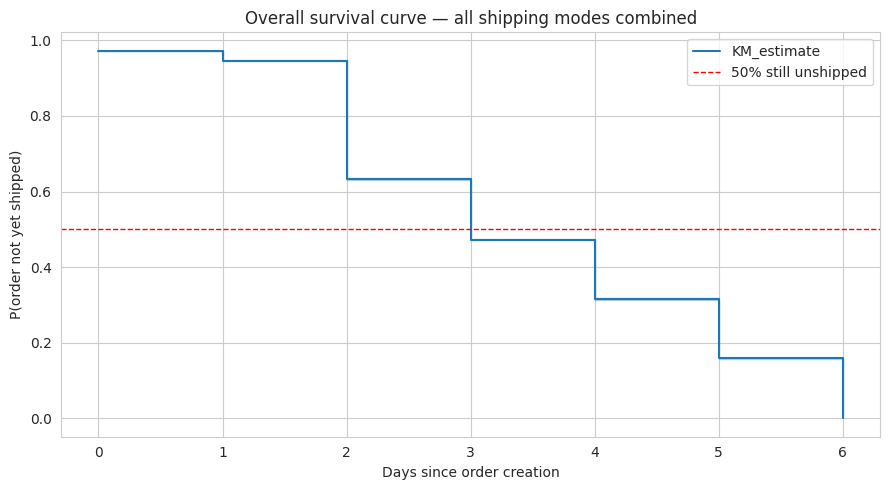

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
kmf_all.plot_survival_function(ax=ax)
ax.axhline(0.5, color='red', linestyle='--', linewidth=1, label='50% still unshipped')
ax.set_xlabel('Days since order creation')
ax.set_ylabel('P(order not yet shipped)')
ax.set_title('Overall survival curve — all shipping modes combined')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/module2_overall_survival.png', dpi=120)
plt.show()


**Operational read:** the table above gives the exact day-by-day probability of an order
still being unshipped. This becomes the basis for an alerting rule — e.g. flag any order that
crosses the day where the cohort-level "still not shipped" probability drops below a chosen
threshold (10–20%), since at that point the order is behaving as an outlier relative to its
peers and warrants manual review.

## 8. Conclusions & limitations

**Findings:**
- Second Class and Standard Class take a statistically indistinguishable number of days to ship
  in absolute terms (log-rank p ≈ 0.41), even though Module 1 found Second Class breaks its own
  promised window by ~2 more days. The delay problem identified in Module 1 is about the
  promise, not about the operation being structurally slower for Second Class.
- Shipping mode dominates the hazard of fulfillment time (C-index ≈ 0.69); region and customer
  segment contribute comparatively little.

**Limitations:**
- **No real censoring** exists in this historical, fully-completed extract — every order has a
  recorded shipment date. In a live system, in-progress orders would be subject to real censoring, and
  the Kaplan-Meier / Cox setup here should be re-validated against that scenario rather than
  assumed to transfer directly.
- The proportional hazards assumption is violated for First Class and Same Day specifically,
  due to the deterministic scheduling artifact identified in Module 1 — the Cox hazard ratios
  for those two categories should be read qualitatively, not as precise multiplicative effects.
- As in Module 1, this remains observational data; the hazard ratios describe association within
  the model, not a guaranteed causal mechanism.